# FaceUnlock: face verification CNN

Pipeline: data setup, EDA, preprocessing, model training, evaluation.

Runs on a Mac (cheap cells, local data) and on Google Colab (training, data from Kaggle).

## 1. Setup and data location

`IN_COLAB` is `True` only on Colab. On Colab we download LFW (Labeled Faces in the Wild) from Kaggle; locally we use the copy in `data/lfw`.

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import kagglehub
    LFW_ROOT = Path(kagglehub.dataset_download("jessicali9530/lfw-dataset"))
else:
    LFW_ROOT = Path("../data/lfw")

FACES_DIR = LFW_ROOT / "lfw-deepfunneled" / "lfw-deepfunneled"
print(FACES_DIR, "exists:", FACES_DIR.exists())

../data/lfw/lfw-deepfunneled/lfw-deepfunneled exists: True


## 2. EDA: photos per person

Face verification needs several photos of the same person. This shows how many people have enough.

count    5749.000000
mean        2.301792
std         9.016410
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       530.000000
dtype: float64
George_W_Bush        530
Colin_Powell         236
Tony_Blair           144
Donald_Rumsfeld      121
Gerhard_Schroeder    109
Ariel_Sharon          77
Hugo_Chavez           71
Junichiro_Koizumi     60
Jean_Chretien         55
John_Ashcroft         53
dtype: int64
People with 2+ photos: 1680


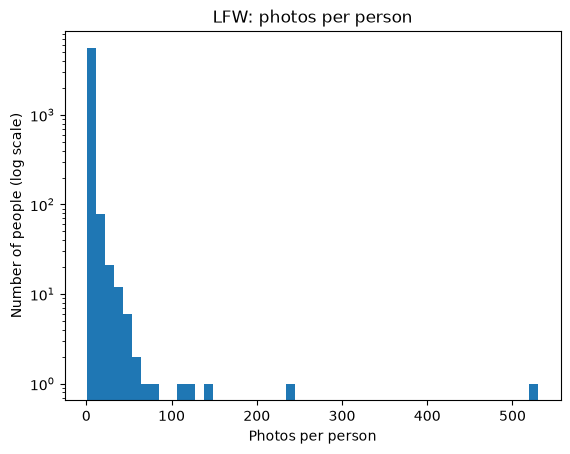

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

counts = pd.Series(
    {p.name: len(list(p.glob("*.jpg"))) for p in FACES_DIR.iterdir() if p.is_dir()}
).sort_values(ascending=False)

print(counts.describe())
print(counts.head(10))
print("People with 2+ photos:", (counts >= 2).sum())

counts.plot(kind="hist", bins=50, log=True)
plt.xlabel("Photos per person")
plt.ylabel("Number of people (log scale)")
plt.title("LFW: photos per person")
plt.show()